# Proyecto Final - Módulo 1
## Ciencia de Datos con Python
### Nestor Daniel Alexander Escobedo Peralta - 2052273
#### https://github.com/Netza-byte/Proyecto-Python-Ciencia_de_Datos

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# Dataset de Pokemon
df = pd.read_csv('Pokemon.csv')

# Dimensiones Iniciales
print(f'Dimensiones del dataset: {df.shape[0]} filas y {df.shape[1]} columnas')

# Primeras filas del conjunto de datos
df.head()

Dimensiones del dataset: 800 filas y 13 columnas


,#,Name,Type 1,Type 2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary
0,1,Bulbasaur,Grass,Poison,318,45,49,49,65,65,45,1,False
1,2,Ivysaur,Grass,Poison,405,60,62,63,80,80,60,1,False
2,3,Venusaur,Grass,Poison,525,80,82,83,100,100,80,1,False
3,3,VenusaurMega Venusaur,Grass,Poison,625,80,100,123,122,120,80,1,False
4,4,Charmander,Fire,NaN,309,39,52,43,60,50,65,1,False


In [ ]:
# Conteo de valores nulos por columna
print('> Valores nulos por columna <')
print(df.isnull().sum())

# Conteo de filas duplicadas en el dataset
duplicados = df.duplicated().sum()
print(f'\nTotal de filas duplicadas encontradas: {duplicados}')

> Valores nulos por columna <
#               0
Name            0
Type 1          0
Type 2        386
Total           0
HP              0
Attack          0
Defense         0
Sp. Atk         0
Sp. Def         0
Speed           0
Generation      0
Legendary       0
dtype: int64

Total de filas duplicadas encontradas: 0


In [ ]:
# Eliminar duplicados
df = df.drop_duplicates()

# Tratar valores nulos en 'Type 2'
df['Type 2'] = df['Type 2'].fillna('Mono-Type')

# Comprobación final de nulos
print('Total de nulos después de la limpieza:', df.isnull().sum().sum())
print(f'Dimensiones finales del dataset: {df.shape}')

Total de nulos después de la limpieza: 0
Dimensiones finales del dataset: (800, 13)


In [ ]:
# KPI-1: Totales
total_pokemon = len(df)
total_legendarios = (df['Legendary'] == True).sum()
total_comunes = (df['Legendary'] == False).sum()

# KPI-2: Promedios generales de combate
promedio_total = df['Total'].mean()
promedio_ataque = df['Attack'].mean()
promedio_defensa = df['Defense'].mean()
promedio_velocidad = df['Speed'].mean()

# KPI-3: Crecimiento porcentual entre Generación 1 y Generación 6
prom_gen1 = df[df['Generation'] == 1]['Total'].mean()
prom_gen6 = df[df['Generation'] == 6]['Total'].mean()
tasa_crecimiento = ((prom_gen6 - prom_gen1) / prom_gen1) * 100

# Despliegue de métricas
print('> DASHBOARD DE KPIS <')
print(f'Total de Pokemon analizados: {total_pokemon}')
print(f'Pokemon comunes: {total_comunes} | Legendarios: {total_legendarios}')
print(f'Poder total promedio: {promedio_total:.2f} pts')
print(f'Ataque promedio: {promedio_ataque:.2f} pts')
print(f'Defensa promedio: {promedio_defensa:.2f} pts')
print(f'Velocidad promedio: {promedio_velocidad:.2f} pts')
print('---------------------------------------')
print(f'Promedio Poder Gen 1: {prom_gen1:.2f} pts')
print(f'Promedio Poder Gen 6: {prom_gen6:.2f} pts')
print(f'Tasa de crecimiento (Gen 1 a Gen 6): {tasa_crecimiento:.2f}%')

> DASHBOARD DE KPIS <
Total de Pokemon analizados: 800
Pokemon comunes: 735 | Legendarios: 65
Poder total promedio: 435.10 pts
Ataque promedio: 79.00 pts
Defensa promedio: 73.84 pts
Velocidad promedio: 68.28 pts
---------------------------------------
Promedio Poder Gen 1: 426.81 pts
Promedio Poder Gen 6: 436.38 pts
Tasa de crecimiento (Gen 1 a Gen 6): 2.24%


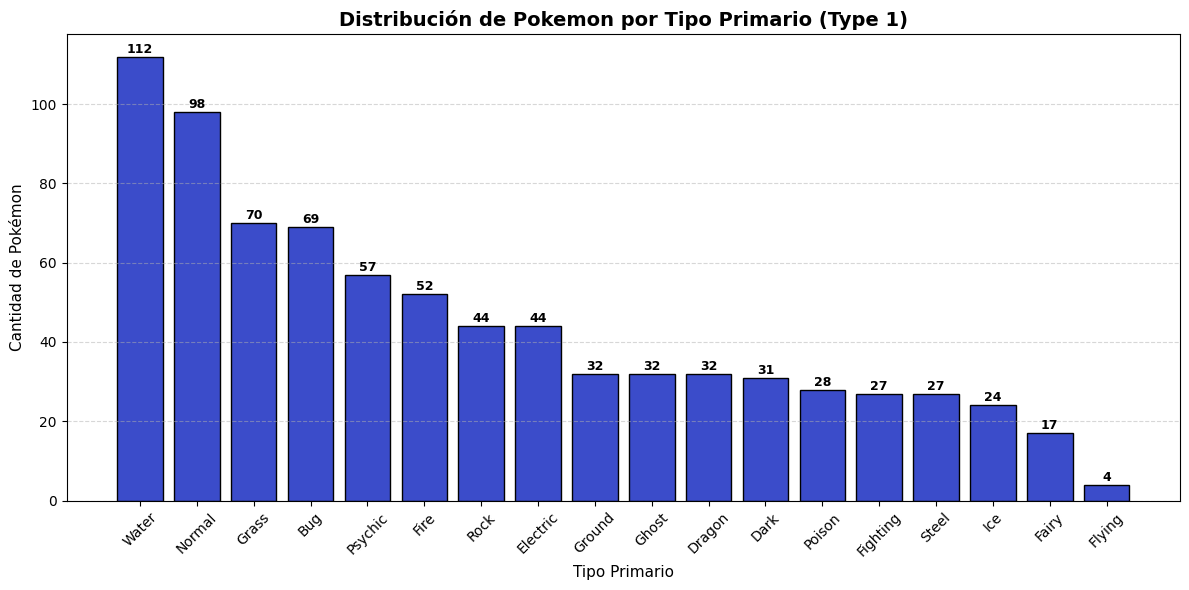

In [ ]:
# Conteo de Pokémon por tipo primario (Type 1)
conteo_tipos = df['Type 1'].value_counts()

# Configuración del gráfico
plt.figure(figsize=(12, 6))
barras = plt.bar(
    conteo_tipos.index, conteo_tipos.values, color='#3B4CCA', edgecolor='black'
)

# Añadir etiquetas con el valor numérico sobre cada barra
for b in barras:
  altura = b.get_height()
  plt.text(
      b.get_x() + b.get_width() / 2,
      altura + 1,
      str(altura),
      ha='center',
      fontsize=9,
      fontweight='bold',
  )

# Personalización del gráfico
plt.title(
    'Distribución de Pokemon por Tipo Primario (Type 1)',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Tipo Primario', fontsize=11)
plt.ylabel('Cantidad de Pokémon', fontsize=11)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

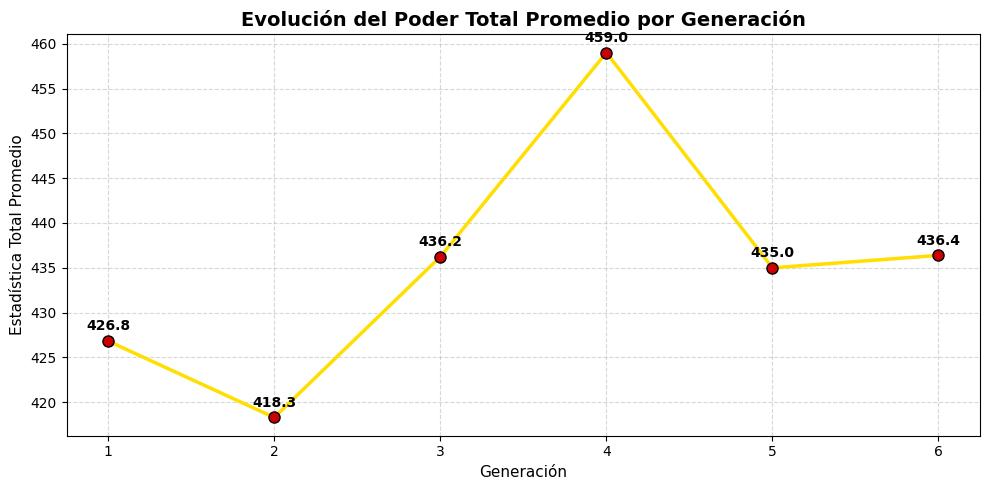

In [ ]:
# Promedio de estadísticas totales por generación
promedio_por_gen = df.groupby('Generation')['Total'].mean()

# Configuración del gráfico
plt.figure(figsize=(10, 5))
plt.plot(
    promedio_por_gen.index,
    promedio_por_gen.values,
    color='#FFDE00',
    marker='o',
    linestyle='-',
    linewidth=2.5,
    markersize=8,
    markerfacecolor='#CC0000',
    markeredgecolor='black',
)

# Añadir etiquetas numéricas
for gen, valor in zip(promedio_por_gen.index, promedio_por_gen.values):
  plt.text(
      gen,
      valor + 1.2,
      f'{valor:.1f}',
      ha='center',
      fontsize=10,
      fontweight='bold',
  )

# Personalización del gráfico
plt.title(
    'Evolución del Poder Total Promedio por Generación',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Generación', fontsize=11)
plt.ylabel('Estadística Total Promedio', fontsize=11)
plt.xticks(promedio_por_gen.index)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

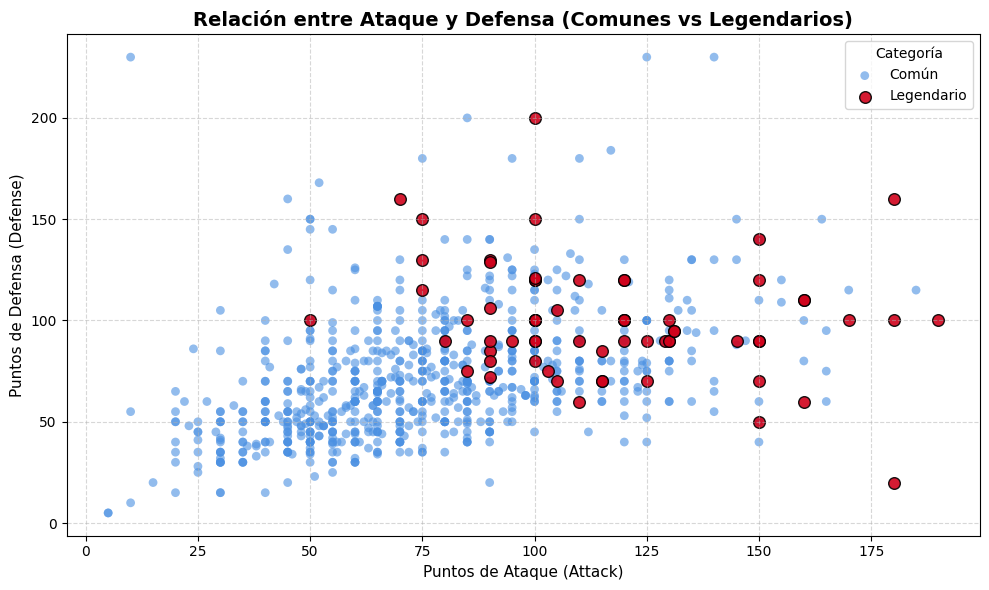

In [ ]:
# Separar datos entre Pokemon normales y legendarios
normales = df[df['Legendary'] == False]
legendarios = df[df['Legendary'] == True]

# Configuración del gráfico
plt.figure(figsize=(10, 6))

# Puntos de Pokemon comunes
plt.scatter(
    normales['Attack'],
    normales['Defense'],
    color='#4A90E2',
    alpha=0.6,
    s=40,
    edgecolor='none',
    label='Común',
)

# Puntos de Pokemon legendarios
plt.scatter(
    legendarios['Attack'],
    legendarios['Defense'],
    color='#D0021B',
    alpha=0.9,
    s=70,
    edgecolor='black',
    label='Legendario',
)

# Personalización del gráfico
plt.title(
    'Relación entre Ataque y Defensa (Comunes vs Legendarios)',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Puntos de Ataque (Attack)', fontsize=11)
plt.ylabel('Puntos de Defensa (Defense)', fontsize=11)
plt.legend(title='Categoría')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()